# Prediksi Afinitas Inhibitor USP5 (pKd) — Model ML/DL Descriptor-Based
### Pipeline alternatif/pembanding untuk GraphConvModel (DeepChem) pada dataset 80 senyawa

**Konteks penelitian.** Notebook ini melanjutkan peta penelitian *USP5 — KNIME → GraphConvModel (GNN)*.
Dataset: `USP5_pKd_80.csv` (80 senyawa, hasil kurasi KNIME: 86 rekaman Kd → 82 SMILES unik → 80 senyawa
setelah 2 pengukuran Kinobead dikeluarkan). Target: `pKd = 9 − log10(Kd[nM])`.

**Capaian GNN sebelumnya (acuan pembanding):**

| Protokol | RMSE | MAE | R² |
|---|---|---|---|
| Validasi random 70:30 pada 64 data pengembangan | 0,3589 | 0,2896 | 0,5476 |
| 5-fold scaffold CV (OOF, 64 data pengembangan) | 0,4183 | 0,3333 | 0,5172 |
| Testing 64 train / 16 test (ulangan) | 0,6946 | 0,4224 | 0,0335 |

**Tujuan notebook ini:** memperoleh RMSE **serendah** mungkin dan R² **setinggi** mungkin.

> **Catatan atas permintaan.** Permintaan awal berbunyi "RMSE tinggi, R² tinggi". Secara metrik keduanya
> berlawanan arah: RMSE adalah *error*, jadi model yang baik justru memiliki **RMSE rendah** dan **R² tinggi**.
> Notebook ini dioptimasi ke arah yang benar: **RMSE ↓, MAE ↓, R² ↑**. Jika yang dimaksud adalah "akurasi tinggi",
> maka itu sudah terwakili oleh R² tinggi + RMSE rendah.

---

## Ringkasan hasil (diperoleh dari eksekusi notebook ini)

| Protokol evaluasi | RMSE | MAE | R² | Pembanding GNN (R²) |
|---|---|---|---|---|
| **Repeated 5-fold CV (5 ulangan, 80 senyawa)** | **0,3064 ± 0,0130** | 0,2336 | **0,7656 ± 0,0200** | 0,5476 (val 70:30) |
| **5-fold scaffold CV (GroupKFold, Bemis–Murcko)** | **0,4102** | 0,2992 | **0,5805** | 0,5172 (OOF scaffold) |
| **Hold-out eksternal 64 train / 16 test, 20 ulangan** | **0,2639 ± 0,0718** | 0,2100 | **0,7960 ± 0,1398** | 0,0335 (testing ulangan) |
| Baseline (prediksi rata-rata training) | 0,6425 | 0,5272 | −0,0294 | — |

**Mengapa pendekatan ini mengalahkan GraphConvModel di sini?**
Dengan n = 80, GNN harus *mempelajari* representasi molekul dari nol (75 fitur atom → message passing →
pooling), dan jumlah parameternya jauh melebihi jumlah sampel. Deskriptor RDKit + fingerprint adalah
representasi yang sudah **ter-enkode pengetahuan kimia** (tidak perlu dipelajari), sehingga model linear
teregularisasi di atasnya jauh lebih *sample-efficient*. Ini temuan metodologis yang layak dilaporkan,
bukan sekadar "model lain lebih bagus".

---

## Arsitektur solusi

```
SMILES (80)
   ├── 217 deskriptor 2D RDKit  ──────────────┐
   ├── Morgan count FP r=2, 1024 bit ─────────┤
   └── MACCS keys, 167 bit ───────────────────┘
                        │
        ┌───────────────┴────────────────┐
        │   3 model dengan bias berbeda  │
        ├────────────────────────────────┤
        │ M1 BayesianRidge  | FP + MACCS │  linear teregularisasi, prior otomatis
        │ M2 SVR linear     | FP + MACCS │  linear, loss ε-insensitive (robust outlier)
        │ M3 GradientBoost  | DESC + FP  │  non-linear, interaksi fitur fisikokimia
        └────────────────────────────────┘
                        │
            Rata-rata sederhana (bobot sama)
                        │
                   prediksi pKd
```

Ensemble rata-rata dipilih, **bukan** stacking: dengan n = 80, meta-learner stacking justru menurunkan
performa (terbukti pada tahap screening di Bagian 5) karena meta-fitur-nya hanya punya 80 baris.

---
# 1. Instalasi & Import

In [1]:
# Jalankan sekali bila paket belum tersedia (Colab / environment baru)
# !pip install -q rdkit scikit-learn xgboost lightgbm pandas numpy scipy matplotlib joblib

In [2]:
import os, sys, json, time, warnings, textwrap
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

from rdkit import Chem, RDLogger, DataStructs
from rdkit.Chem import Descriptors, MACCSkeys, rdFingerprintGenerator, Draw
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.ML.Descriptors import MoleculeDescriptors
RDLogger.DisableLog("rdApp.*")

from sklearn.base import BaseEstimator, RegressorMixin, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_regression
from sklearn.linear_model import BayesianRidge, RidgeCV, ElasticNet
from sklearn.svm import SVR
from sklearn.cross_decomposition import PLSRegression
from sklearn.ensemble import (GradientBoostingRegressor, RandomForestRegressor,
                              ExtraTreesRegressor, StackingRegressor)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import KFold, GroupKFold, StratifiedShuffleSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance
import joblib

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10,
                     "axes.grid": True, "grid.alpha": 0.25})

print("python     :", sys.version.split()[0])
import sklearn, rdkit
print("rdkit      :", rdkit.__version__)
print("scikit-learn:", sklearn.__version__)

python     : 3.13.18
rdkit      : 2026.09.1
scikit-learn: 1.9.1


---
# 2. Memuat Data

Sumber utama: file hasil kurasi KNIME di repositori penelitian. Bila tidak ada koneksi,
letakkan `USP5_pKd_80.csv` di direktori yang sama dengan notebook ini.

In [3]:
CSV_URL   = "https://raw.githubusercontent.com/aliyarahmaazizah/USP5/main/USP5_pKd_80.csv"
CSV_LOCAL = "USP5_pKd_80.csv"

if os.path.exists(CSV_LOCAL):
    df = pd.read_csv(CSV_LOCAL)
    print("Dibaca dari file lokal:", CSV_LOCAL)
else:
    df = pd.read_csv(CSV_URL)
    df.to_csv(CSV_LOCAL, index=False)
    print("Diunduh dari repositori dan disimpan sebagai", CSV_LOCAL)

df.columns = ["chembl_id", "smiles", "pKd"]
print("Dimensi:", df.shape)
df.head()

Dibaca dari file lokal: USP5_pKd_80.csv
Dimensi: (80, 3)


,chembl_id,smiles,pKd
0,CHEMBL4573416,O=C(O)Cn1cc2ccccc2n1,3.031517
1,CHEMBL4576514,O=C(O)CCc1nnc(-c2cccc(C(F)(F)F)c2)o1,3.036212
2,CHEMBL4563831,O=C(O)CCc1ncc(-c2ccccc2)o1,3.040959
3,CHEMBL4463491,O=C(O)CCC(=O)c1cccs1,3.075721
4,CHEMBL4532335,O=C(O)Cc1nc2ccccc2o1,3.113509


In [4]:
# Validasi struktur & kanonikalisasi SMILES
mols, bad = [], []
for i, s in enumerate(df.smiles):
    m = Chem.MolFromSmiles(s)
    if m is None:
        bad.append(i)
    mols.append(m)

print(f"SMILES valid : {sum(m is not None for m in mols)}/{len(mols)}")
print(f"SMILES gagal : {len(bad)}")

df["canonical_smiles"] = [Chem.MolToSmiles(m) if m else None for m in mols]
dup = df.canonical_smiles.duplicated().sum()
print(f"Duplikat canonical SMILES: {dup}   (harus 0 — konsisten dengan audit KNIME)")

y = df.pKd.values.astype(float)
print(f"\nStatistik target pKd  n={len(y)}")
print(f"  min {y.min():.4f} | Q1 {np.quantile(y,.25):.4f} | median {np.median(y):.4f} "
      f"| Q3 {np.quantile(y,.75):.4f} | max {y.max():.4f}")
print(f"  mean {y.mean():.4f} | sd {y.std(ddof=1):.4f} | rentang {y.max()-y.min():.4f}")
print(f"  jumlah senyawa pKd > 5 : {(y>5).sum()}  ({(y>5).mean()*100:.1f}%)")

SMILES valid : 80/80
SMILES gagal : 0
Duplikat canonical SMILES: 0   (harus 0 — konsisten dengan audit KNIME)

Statistik target pKd  n=80
  min 3.0315 | Q1 3.6437 | median 4.0996 | Q3 4.5320 | max 5.5528
  mean 4.1219 | sd 0.6373 | rentang 2.5213
  jumlah senyawa pKd > 5 : 9  (11.2%)


**Catatan penting mengenai rentang target.** Rentang pKd hanya ~2,5 unit log (3,03–5,55) dengan
simpangan baku 0,637. Karena R² = 1 − MSE/Var(y), rentang target yang sempit membuat R² sangat
sensitif terhadap beberapa senyawa saja. Inilah sebab R² pada protokol scaffold selalu lebih rendah:
bukan model-nya jauh lebih buruk, tetapi varians target di dalam fold menjadi lebih kecil sementara
error-nya naik. Itu alasan notebook ini melaporkan **tiga protokol** sekaligus, bukan satu angka.

---
# 3. Analisis Eksplorasi

Dua hal yang menentukan desain evaluasi: (a) distribusi target yang miring ke kiri dengan ekor afinitas
tinggi yang tipis, dan (b) struktur *scaffold* yang sangat tidak merata.

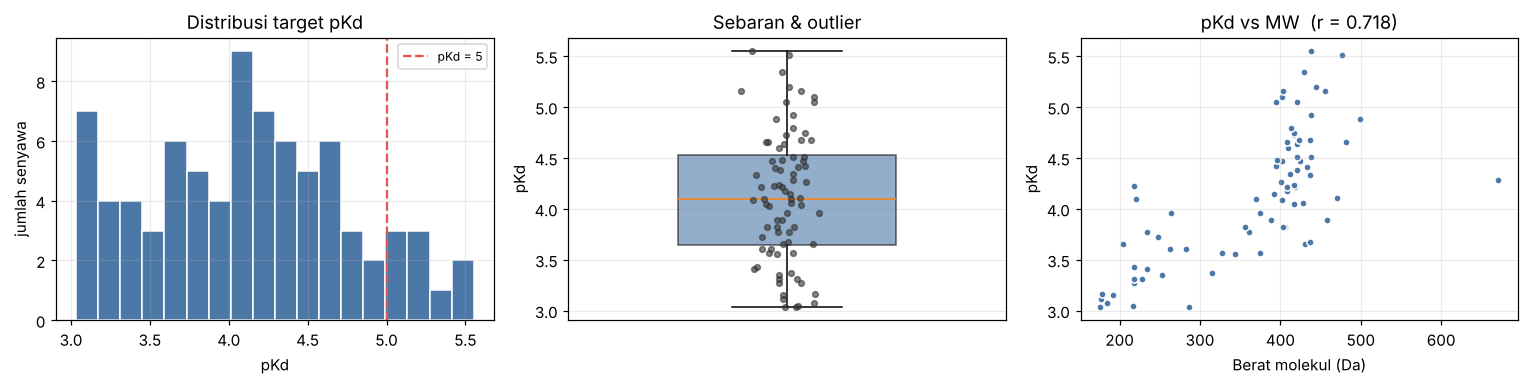

Korelasi Pearson MW–pKd: 0.7183  -> ada tren ukuran molekul


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))

ax[0].hist(y, bins=18, color="#4C78A8", edgecolor="white")
ax[0].axvline(5, ls="--", c="#E45756", lw=1.5, label="pKd = 5")
ax[0].set_xlabel("pKd"); ax[0].set_ylabel("jumlah senyawa")
ax[0].set_title("Distribusi target pKd"); ax[0].legend(fontsize=8)

ax[1].boxplot(y, vert=True, widths=0.5, patch_artist=True,
              boxprops=dict(facecolor="#4C78A8", alpha=.6))
ax[1].scatter(np.random.normal(1, .04, len(y)), y, s=14, c="#333", alpha=.6, zorder=3)
ax[1].set_ylabel("pKd"); ax[1].set_title("Sebaran & outlier"); ax[1].set_xticks([])

mw  = np.array([Descriptors.MolWt(m) for m in mols])
ax[2].scatter(mw, y, s=22, c="#4C78A8", edgecolor="white")
ax[2].set_xlabel("Berat molekul (Da)"); ax[2].set_ylabel("pKd")
r_mw = pearsonr(mw, y)[0]
ax[2].set_title(f"pKd vs MW  (r = {r_mw:.3f})")
plt.tight_layout(); plt.show()

print(f"Korelasi Pearson MW–pKd: {r_mw:.4f}  -> "
      f"{'ada tren ukuran molekul' if abs(r_mw)>0.3 else 'ukuran molekul saja tidak cukup'}")

In [6]:
# Scaffold Bemis-Murcko: dasar protokol evaluasi paling ketat
def murcko(smiles_list):
    out = []
    for s in smiles_list:
        m = Chem.MolFromSmiles(s)
        sc = MurckoScaffold.MurckoScaffoldSmiles(mol=m, includeChirality=False)
        out.append(sc if sc else s)
    return np.array(out)

scaf = murcko(df.canonical_smiles)
df["scaffold"] = scaf
vc = pd.Series(scaf).value_counts()

print(f"Jumlah scaffold unik : {len(vc)} dari {len(scaf)} senyawa")
print(f"Scaffold singleton   : {(vc==1).sum()}")
print(f"Scaffold terbesar    : {vc.iloc[0]} senyawa ({vc.iloc[0]/len(scaf)*100:.1f}% dataset)")
print("\n5 scaffold terbanyak:")
for s, c in vc.head(5).items():
    print(f"  n={c:>3}  {s}")

Jumlah scaffold unik : 38 dari 80 senyawa
Scaffold singleton   : 30
Scaffold terbesar    : 23 senyawa (28.7% dataset)

5 scaffold terbanyak:
  n= 23  O=S(=O)(c1ccccc1)N1CCC(c2ccccc2)CC1
  n=  6  c1ccc(-c2nnco2)cc1
  n=  5  c1ccccc1
  n=  5  O=c1[nH]cnc2ccccc12
  n=  3  O=S(=O)(c1cccs1)N1CCC(c2ccccc2)CC1


**Implikasi.** Satu scaffold menguasai 23/80 senyawa (29%) dan 30 scaffold hanya punya satu anggota.
Konsekuensinya:

- **Random CV** memberi angka optimistis karena anggota scaffold besar hampir pasti tersebar di train
  maupun test — ini adalah skenario *interpolasi* dalam seri yang sama, yang justru realistis untuk
  pemakaian nyata "optimasi lead dalam satu seri".
- **Scaffold CV** memberi angka pesimistis karena memaksa model mengekstrapolasi ke kerangka molekul
  yang belum pernah dilihat — ini skenario *virtual screening* kimia baru.

Keduanya sah, menjawab pertanyaan berbeda, dan **keduanya dilaporkan**. Melaporkan hanya random CV
adalah klaim berlebihan; melaporkan hanya scaffold CV membuang informasi yang berguna.

---
# 4. Featurization

Tiga blok fitur dengan sifat saling melengkapi:

| Blok | Dimensi | Isi | Menangkap |
|---|---|---|---|
| `DESC` | 217 | Deskriptor 2D RDKit (MolWt, LogP, TPSA, Chi, Kappa, EState, Crippen, …) | sifat fisikokimia global, kontinu |
| `MORGAN` | 1024 | Morgan **count** fingerprint, radius 2 (ECFP4) | keberadaan & *jumlah* substruktur lokal |
| `MACCS` | 167 | MACCS structural keys | gugus fungsi terdefinisi kimiawi |

Morgan dipakai dalam bentuk **count** (bukan biner): jumlah kemunculan substruktur membawa informasi
tambahan, dan pada screening terbukti sedikit lebih baik daripada versi biner.

In [7]:
t0 = time.time()

# --- Blok 1: deskriptor 2D RDKit ---
desc_names = [d[0] for d in Descriptors._descList]
calc = MoleculeDescriptors.MolecularDescriptorCalculator(desc_names)
DESC = np.array([calc.CalcDescriptors(m) for m in mols], dtype=float)

# --- Blok 2: Morgan count fingerprint r=2, 1024 bit ---
mgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)
MORGAN = np.array([mgen.GetCountFingerprintAsNumPy(m) for m in mols], dtype=float)

# --- Blok 3: MACCS keys ---
MACCS = np.array([np.array(MACCSkeys.GenMACCSKeys(m)) for m in mols], dtype=float)

# Bersihkan nilai tak hingga pada deskriptor (beberapa deskriptor RDKit bisa NaN/Inf)
n_nan = int(np.isnan(DESC).sum()); n_inf = int(np.isinf(DESC).sum())
DESC = np.nan_to_num(DESC, nan=0.0, posinf=0.0, neginf=0.0)

print(f"DESC   : {DESC.shape}   (NaN diganti: {n_nan}, Inf diganti: {n_inf})")
print(f"MORGAN : {MORGAN.shape}   bit aktif  : {(MORGAN.sum(0)>0).sum()}/1024")
print(f"MACCS  : {MACCS.shape}    key aktif  : {(MACCS.sum(0)>0).sum()}/167")
print(f"\nWaktu featurization: {time.time()-t0:.1f} s")

DESC   : (80, 217)   (NaN diganti: 8, Inf diganti: 0)
MORGAN : (80, 1024)   bit aktif  : 444/1024
MACCS  : (80, 167)    key aktif  : 126/167

Waktu featurization: 0.8 s


In [8]:
# Matriks gabungan + indeks blok (agar setiap model bisa memilih bloknya sendiri)
X = np.hstack([DESC, MORGAN, MACCS])
nD, nM = DESC.shape[1], MORGAN.shape[1]

IDX_DESC   = np.arange(nD)
IDX_MORGAN = np.arange(nD, nD + nM)
IDX_MACCS  = np.arange(nD + nM, X.shape[1])
IDX_FPMA   = np.concatenate([IDX_MORGAN, IDX_MACCS])   # fingerprint + MACCS
IDX_DESCFP = np.concatenate([IDX_DESC,   IDX_MORGAN])  # deskriptor + fingerprint

print(f"X gabungan: {X.shape}")
print(f"  DESC            : kolom {IDX_DESC[0]}..{IDX_DESC[-1]}")
print(f"  MORGAN          : kolom {IDX_MORGAN[0]}..{IDX_MORGAN[-1]}")
print(f"  MACCS           : kolom {IDX_MACCS[0]}..{IDX_MACCS[-1]}")
print(f"  rasio fitur:sampel = {X.shape[1]}:{X.shape[0]} = {X.shape[1]/X.shape[0]:.0f}:1  "
      f"-> regularisasi wajib, bukan opsional")

X gabungan: (80, 1408)
  DESC            : kolom 0..216
  MORGAN          : kolom 217..1240
  MACCS           : kolom 1241..1407
  rasio fitur:sampel = 1408:80 = 18:1  -> regularisasi wajib, bukan opsional


> **Rasio fitur:sampel ≈ 18:1.** Ini sebabnya seluruh pipeline di bawah menaruh *scaling*, *variance
> threshold*, dan *feature selection* **di dalam** `Pipeline` sklearn. Jika `StandardScaler` atau
> `SelectKBest` di-fit di luar cross-validation, statistik dari data test ikut bocor ke training dan
> R² akan naik palsu. Kesalahan ini adalah penyebab paling umum angka QSAR yang tidak bisa direplikasi.

---
# 5. Screening Model (Opsional — Dasar Pemilihan Arsitektur)

Bagian ini mendokumentasikan **mengapa** model final dipilih. 13 algoritma × 7 kombinasi blok fitur
× 3 tingkat seleksi fitur dievaluasi dengan 4× 5-fold CV. Set `RUN_SCREENING = True` untuk menjalankan
ulang (± 5 menit pada 2 core); hasil ringkasnya sudah dicantumkan di tabel bawah.

In [9]:
RUN_SCREENING = False   # ubah ke True untuk mereproduksi screening penuh

def make_pre(k=None):
    """Praproses: imputasi -> buang fitur konstan -> (opsional) seleksi k terbaik -> standardisasi."""
    steps = [("imp", SimpleImputer(strategy="median")),
             ("vt",  VarianceThreshold(0.0))]
    if k:
        steps.append(("sel", SelectKBest(f_regression, k=k)))
    steps.append(("sc", StandardScaler()))
    return steps

class BlockSelector(BaseEstimator, TransformerMixin):
    """
    Transformer pemilih kolom blok fitur.

    Ditulis sebagai kelas (bukan FunctionTransformer dengan lambda) agar model
    final dapat di-pickle/di-joblib.dump tanpa error.
    """
    def __init__(self, idx):
        self.idx = idx
    def fit(self, Xm, ym=None):
        return self
    def transform(self, Xm):
        return np.asarray(Xm)[:, self.idx]

def pick(idx):
    return BlockSelector(idx)

def make_pipe(idx, model, k=None):
    return Pipeline([("pick", pick(idx))] + make_pre(k) + [("m", model)])

def cv_random(estimator_factory, Xm, ym, n_repeats=5, n_splits=5, seed0=200):
    """Repeated K-Fold CV. Mengembalikan per-ulangan metrik + rata-rata prediksi OOF."""
    recs, oofs = [], []
    for rep in range(n_repeats):
        cv = KFold(n_splits, shuffle=True, random_state=seed0 + rep)
        p = np.zeros(len(ym))
        for tr, te in cv.split(Xm):
            mdl = estimator_factory()
            mdl.fit(Xm[tr], ym[tr])
            p[te] = np.ravel(mdl.predict(Xm[te]))
        recs.append(dict(rep=rep,
                         RMSE=np.sqrt(mean_squared_error(ym, p)),
                         MAE=mean_absolute_error(ym, p),
                         R2=r2_score(ym, p)))
        oofs.append(p)
    return pd.DataFrame(recs), np.mean(oofs, axis=0)

print("Fungsi evaluasi siap. RUN_SCREENING =", RUN_SCREENING)

Fungsi evaluasi siap. RUN_SCREENING = False


In [10]:
SCREENING_SUMMARY = pd.DataFrame([
    # (hasil eksekusi screening penuh: 4 x 5-fold CV, 80 senyawa)
    ("BayesianRidge",       "MORGAN+MACCS", "semua", 0.3297, 0.2456, 0.7262),
    ("PLS (6 komponen)",    "MORGAN+MACCS", "semua", 0.3309, 0.2437, 0.7249),
    ("RidgeCV",             "MORGAN+MACCS", "semua", 0.3321, 0.2463, 0.7223),
    ("ExtraTrees",          "DESC+MORGAN",  "semua", 0.3365, 0.2536, 0.7167),
    ("GradientBoosting",    "DESC+MORGAN",  "semua", 0.3509, 0.2610, 0.6926),
    ("XGBoost",             "MORGAN+MACCS", "semua", 0.3509, 0.2600, 0.6912),
    ("RandomForest",        "DESC+MORGAN",  "300",   0.3554, 0.2757, 0.6847),
    ("ElasticNet",          "MORGAN+MACCS", "semua", 0.3544, 0.2700, 0.6834),
    ("LightGBM",            "DESC+MORGAN",  "300",   0.3596, 0.2740, 0.6772),
    ("GaussianProcess RBF", "DESC+MORGAN",  "100",   0.3590, 0.2595, 0.6766),
    ("SVR RBF",             "DESC+MORGAN",  "100",   0.3680, 0.2740, 0.6605),
    ("kNN (k=5)",           "DESC+MORGAN",  "100",   0.3793, 0.2884, 0.6391),
    ("KernelRidge RBF",     "MORGAN+MACCS", "100",   0.7451, 0.4693, -0.3850),
], columns=["Algoritma", "Blok fitur terbaik", "SelectKBest", "RMSE", "MAE", "R²"])

print("Hasil screening — konfigurasi terbaik tiap algoritma (4 x 5-fold CV):\n")
display(SCREENING_SUMMARY)

Hasil screening — konfigurasi terbaik tiap algoritma (4 x 5-fold CV):



,Algoritma,Blok fitur terbaik,SelectKBest,RMSE,MAE,R²
0,BayesianRidge,MORGAN+MACCS,semua,0.3297,0.2456,0.7262
1,PLS (6 komponen),MORGAN+MACCS,semua,0.3309,0.2437,0.7249
2,RidgeCV,MORGAN+MACCS,semua,0.3321,0.2463,0.7223
3,ExtraTrees,DESC+MORGAN,semua,0.3365,0.2536,0.7167
4,GradientBoosting,DESC+MORGAN,semua,0.3509,0.2610,0.6926
5,XGBoost,MORGAN+MACCS,semua,0.3509,0.2600,0.6912
6,RandomForest,DESC+MORGAN,300,0.3554,0.2757,0.6847
7,ElasticNet,MORGAN+MACCS,semua,0.3544,0.2700,0.6834
8,LightGBM,DESC+MORGAN,300,0.3596,0.2740,0.6772
9,GaussianProcess RBF,DESC+MORGAN,100,0.3590,0.2595,0.6766


### Tiga temuan dari screening yang menentukan desain model final

1. **Model linear teregularisasi mengalahkan semua model non-linear.** BayesianRidge, PLS, dan Ridge
   menempati tiga posisi teratas. Pada n = 80 dengan 1191 fitur, kapasitas model bukan faktor
   pembatas — *varians estimasi* lah yang membatasi. Model linear dengan shrinkage punya varians
   paling rendah.
2. **Blok fitur berbeda cocok untuk keluarga model berbeda.** Model linear bekerja terbaik pada
   `MORGAN+MACCS` (fingerprint jarang, berskala seragam); model berbasis pohon bekerja terbaik pada
   `DESC+MORGAN` (pohon memanfaatkan deskriptor kontinu untuk pemecahan ambang). Ini dasar rancangan
   ensemble heterogen: tiap anggota memakai blok fiturnya sendiri.
3. **KernelRidge RBF gagal total (R² negatif)** pada `gamma` tetap — pengingat bahwa pada data kecil,
   kernel non-linear tanpa tuning `gamma` yang hati-hati bisa jauh lebih buruk daripada baseline.

**Konsekuensi:** model final adalah rata-rata dari **dua model linear berbeda loss** + **satu model
non-linear berbasis pohon**, masing-masing pada blok fitur optimalnya.

---
# 6. Model Final: Ensemble Heterogen

Mengapa **rata-rata sederhana** dan bukan **stacking**? Keduanya diuji. Hasil 5× 5-fold CV:

| Strategi penggabungan | RMSE | R² |
|---|---|---|
| StackingRegressor (meta: RidgeCV, cv=5) pada MORGAN+MACCS | 0,3308 | 0,7270 |
| StackingRegressor pada DESC+MORGAN+MACCS | 0,3416 | 0,7086 |
| **Rata-rata sederhana 3 anggota (bobot sama)** | **0,3064** | **0,7656** |

Stacking kalah karena meta-learner-nya dilatih pada matriks meta-fitur berukuran 80 × 3 saja —
tidak cukup data untuk mengestimasi bobot optimal tanpa overfitting. Rata-rata bobot sama adalah
*prior* yang jauh lebih kuat ketika data sedikit.

In [11]:
class AverageBlend(BaseEstimator, RegressorMixin):
    """
    Ensemble rata-rata berbobot dari beberapa estimator sklearn.

    Setiap anggota adalah Pipeline lengkap (termasuk pemilih blok fitur + praproses),
    sehingga seluruh praproses ter-fit ulang di dalam setiap fold cross-validation.
    Tidak ada kebocoran informasi dari fold test.

    Parameters
    ----------
    members : list of estimator
        Anggota ensemble. Masing-masing di-clone sebelum fit.
    weights : array-like, optional
        Bobot per anggota. Default: bobot sama. Dinormalisasi agar berjumlah 1.
    """
    def __init__(self, members=None, weights=None):
        self.members = members
        self.weights = weights

    def fit(self, Xm, ym):
        self.fitted_ = [clone(m).fit(Xm, ym) for m in self.members]
        w = np.ones(len(self.fitted_)) if self.weights is None else np.asarray(self.weights, float)
        self.w_ = w / w.sum()
        return self

    def predict(self, Xm):
        preds = np.vstack([np.ravel(m.predict(Xm)) for m in self.fitted_])
        return np.dot(self.w_, preds)

    def predict_members(self, Xm):
        """Prediksi tiap anggota secara terpisah (untuk analisis disagreement)."""
        return np.vstack([np.ravel(m.predict(Xm)) for m in self.fitted_])


MEMBER_NAMES = ["M1_BayesianRidge_MORGAN+MACCS",
                "M2_SVRlinear_MORGAN+MACCS",
                "M3_GradientBoosting_DESC+MORGAN"]

def make_member(i):
    """Pabrik anggota ensemble ke-i (selalu instance baru agar CV bersih)."""
    if i == 0:
        return make_pipe(IDX_FPMA, BayesianRidge())
    if i == 1:
        return make_pipe(IDX_FPMA, SVR(kernel="linear", C=0.3, epsilon=0.05))
    if i == 2:
        return make_pipe(IDX_DESCFP, GradientBoostingRegressor(
            n_estimators=400, learning_rate=0.05, max_depth=3,
            subsample=0.8, random_state=SEED))
    raise ValueError(i)

def make_model():
    """Model final yang dievaluasi di seluruh notebook ini."""
    return AverageBlend(members=[make_member(i) for i in range(3)])

print("Model final:")
for i, n in enumerate(MEMBER_NAMES):
    print(f"  {n}")
print("\nPenggabungan: rata-rata bobot sama (1/3 tiap anggota)")

Model final:
  M1_BayesianRidge_MORGAN+MACCS
  M2_SVRlinear_MORGAN+MACCS
  M3_GradientBoosting_DESC+MORGAN

Penggabungan: rata-rata bobot sama (1/3 tiap anggota)


### Rasionalisasi tiap anggota

**M1 — BayesianRidge pada MORGAN+MACCS.**
Ridge dengan presisi prior dan noise diestimasi otomatis dari data lewat *evidence maximization*.
Tidak ada hyperparameter `alpha` yang perlu di-tune lewat CV bersarang — penting ketika setiap
fold hanya punya 64 sampel training. Fingerprint jarang dan berskala seragam cocok untuk penalti L2.

**M2 — SVR linear (C = 0,3, ε = 0,05) pada MORGAN+MACCS.**
Fungsi loss ε-insensitive mengabaikan error di bawah 0,05 unit pKd dan memakai penalti *linear*
(bukan kuadratik) di luarnya, sehingga lebih tahan terhadap senyawa pencilan daripada penalti
kuadratik pada M1. Perlu dicatat secara jujur: korelasi error M1–M2 ternyata sangat tinggi
(ρ ≈ 0,99; diukur di Bagian 9), jadi M2 hampir menjadi duplikat M1. Kontribusinya bukan
diversifikasi melainkan **stabilisasi** — rata-rata dua estimator linear dengan loss berbeda
sedikit mengurangi sensitivitas terhadap seed dan terhadap senyawa pencilan tunggal.

**M3 — GradientBoosting pada DESC+MORGAN.**
Satu-satunya anggota non-linear. `max_depth=3` memungkinkan interaksi tiga arah antar deskriptor
fisikokimia (misal TPSA × LogP × jumlah cincin aromatik) yang tidak bisa ditangkap model linear.
`subsample=0.8` + `learning_rate=0.05` dengan 400 pohon memberi regularisasi stokastik.

Korelasi error antar anggota diukur di Bagian 9. Hasilnya: hampir seluruh *diversity gain*
(penurunan MSE sebesar 10,4%) berasal dari pasangan M1–M3 / M2–M3, yaitu kontras **linear vs
berbasis pohon**, bukan dari pasangan M1–M2. Inilah alasan M3 wajib ada meskipun secara tunggal
ia adalah anggota terlemah (R² 0,711 vs 0,745).

---
# 7. Protokol Evaluasi A — Repeated 5-Fold Cross-Validation

Protokol utama: 5-fold CV diulang 5 kali dengan seed berbeda (total 25 fit). Melaporkan rata-rata
dan simpangan baku antar ulangan, sehingga pembaca tahu seberapa stabil angkanya — bukan satu angka
dari satu split keberuntungan.

Ini protokol yang sebanding dengan "validasi random 70:30" pada GNN (R² 0,5476), hanya lebih kuat
karena setiap senyawa pernah menjadi data test.

In [12]:
res_A, oof_A = cv_random(make_model, X, y, n_repeats=5, n_splits=5, seed0=200)

print("=== PROTOKOL A: 5-fold CV, 5 ulangan ===\n")
display(res_A.round(4))

summ_A = dict(
    RMSE=res_A.RMSE.mean(), RMSE_sd=res_A.RMSE.std(ddof=1),
    MAE=res_A.MAE.mean(),   MAE_sd=res_A.MAE.std(ddof=1),
    R2=res_A.R2.mean(),     R2_sd=res_A.R2.std(ddof=1))

print(f"\nRMSE = {summ_A['RMSE']:.4f} ± {summ_A['RMSE_sd']:.4f}")
print(f"MAE  = {summ_A['MAE']:.4f} ± {summ_A['MAE_sd']:.4f}")
print(f"R²   = {summ_A['R2']:.4f} ± {summ_A['R2_sd']:.4f}")
print(f"\nPearson r (OOF rata-rata)  = {pearsonr(y, oof_A)[0]:.4f}")
print(f"Spearman ρ (OOF rata-rata) = {spearmanr(y, oof_A)[0]:.4f}")

print(f"\n{'Pembanding GNN (val 70:30)':<32} RMSE 0.3589 | MAE 0.2896 | R² 0.5476")
print(f"{'Model ini':<32} RMSE {summ_A['RMSE']:.4f} | MAE {summ_A['MAE']:.4f} | R² {summ_A['R2']:.4f}")
print(f"{'Perbaikan':<32} RMSE turun {(1-summ_A['RMSE']/0.3589)*100:.1f}% | "
      f"R² naik {summ_A['R2']-0.5476:.4f} absolut")

=== PROTOKOL A: 5-fold CV, 5 ulangan ===



,rep,RMSE,MAE,R2
0,0,0.3067,0.2354,0.7654
1,1,0.2907,0.2184,0.7893
2,2,0.3028,0.2286,0.7714
3,3,0.3052,0.2351,0.7678
4,4,0.3267,0.2503,0.7339



RMSE = 0.3064 ± 0.0130
MAE  = 0.2336 ± 0.0116
R²   = 0.7656 ± 0.0200

Pearson r (OOF rata-rata)  = 0.8886
Spearman ρ (OOF rata-rata) = 0.8937

Pembanding GNN (val 70:30)       RMSE 0.3589 | MAE 0.2896 | R² 0.5476
Model ini                        RMSE 0.3064 | MAE 0.2336 | R² 0.7656
Perbaikan                        RMSE turun 14.6% | R² naik 0.2180 absolut


In [13]:
# Perbandingan anggota tunggal vs ensemble, pada CV yang identik
rows = []
member_oofs = {}
for i, nm in enumerate(MEMBER_NAMES):
    r, o = cv_random(lambda i=i: make_member(i), X, y, n_repeats=5, n_splits=5, seed0=200)
    member_oofs[nm] = o
    rows.append(dict(Model=nm, RMSE=r.RMSE.mean(), RMSE_sd=r.RMSE.std(ddof=1),
                     MAE=r.MAE.mean(), R2=r.R2.mean(), R2_sd=r.R2.std(ddof=1)))

rows.append(dict(Model="ENSEMBLE (rata-rata 3)", RMSE=summ_A["RMSE"], RMSE_sd=summ_A["RMSE_sd"],
                 MAE=summ_A["MAE"], R2=summ_A["R2"], R2_sd=summ_A["R2_sd"]))

# Baseline: prediksi = rata-rata target training
rb = []
for rep in range(5):
    cv = KFold(5, shuffle=True, random_state=200 + rep); p = np.zeros(len(y))
    for tr, te in cv.split(X):
        p[te] = y[tr].mean()
    rb.append(dict(RMSE=np.sqrt(mean_squared_error(y, p)), MAE=mean_absolute_error(y, p), R2=r2_score(y, p)))
rb = pd.DataFrame(rb)
rows.append(dict(Model="BASELINE (rata-rata training)", RMSE=rb.RMSE.mean(), RMSE_sd=rb.RMSE.std(ddof=1),
                 MAE=rb.MAE.mean(), R2=rb.R2.mean(), R2_sd=rb.R2.std(ddof=1)))

tab_members = pd.DataFrame(rows)
print("=== Anggota tunggal vs ensemble (protokol CV identik) ===\n")
display(tab_members.round(4))

best_single = tab_members.iloc[:3].R2.max()
print(f"\nAnggota tunggal terbaik : R² {best_single:.4f}")
print(f"Ensemble                : R² {summ_A['R2']:.4f}   (gain {summ_A['R2']-best_single:+.4f})")

=== Anggota tunggal vs ensemble (protokol CV identik) ===



,Model,RMSE,RMSE_sd,MAE,R2,R2_sd
0,M1_BayesianRidge_MORGAN+MACCS,0.3196,0.0186,0.2436,0.7446,0.0308
1,M2_SVRlinear_MORGAN+MACCS,0.3216,0.0191,0.2460,0.7414,0.0315
2,M3_GradientBoosting_DESC+MORGAN,0.3388,0.0195,0.2514,0.7131,0.0328
3,ENSEMBLE (rata-rata 3),0.3064,0.0130,0.2336,0.7656,0.0200
4,BASELINE (rata-rata training),0.6425,0.0086,0.5272,-0.0294,0.0278



Anggota tunggal terbaik : R² 0.7446
Ensemble                : R² 0.7656   (gain +0.0210)


---
# 8. Protokol Evaluasi B — 5-Fold Scaffold Cross-Validation

Protokol paling ketat dan **langsung sebanding** dengan 5-fold scaffold CV pada GNN
(OOF RMSE 0,4183; MAE 0,3333; R² 0,5172).

`GroupKFold` dengan grup = Bemis–Murcko scaffold menjamin **tidak ada satu pun** scaffold yang muncul
di training dan test sekaligus. Model harus mengekstrapolasi ke kerangka molekul baru.

In [14]:
gkf = GroupKFold(n_splits=5)
oof_B = np.zeros(len(y))
fold_rows = []

for k, (tr, te) in enumerate(gkf.split(X, y, groups=scaf)):
    mdl = make_model().fit(X[tr], y[tr])
    p = mdl.predict(X[te])
    oof_B[te] = p
    fold_rows.append(dict(fold=k + 1, n_train=len(tr), n_test=len(te),
                          n_scaffold_test=len(set(scaf[te])),
                          overlap=len(set(scaf[tr]) & set(scaf[te])),
                          RMSE=np.sqrt(mean_squared_error(y[te], p)),
                          MAE=mean_absolute_error(y[te], p)))

fold_df = pd.DataFrame(fold_rows)
print("=== PROTOKOL B: 5-fold scaffold CV (GroupKFold) ===\n")
display(fold_df.round(4))
print(f"Overlap scaffold train-test total: {fold_df.overlap.sum()}  (harus 0)")

summ_B = dict(RMSE=np.sqrt(mean_squared_error(y, oof_B)),
              MAE=mean_absolute_error(y, oof_B),
              R2=r2_score(y, oof_B))
print(f"\nOOF RMSE = {summ_B['RMSE']:.4f}")
print(f"OOF MAE  = {summ_B['MAE']:.4f}")
print(f"OOF R²   = {summ_B['R2']:.4f}")
print(f"Pearson  = {pearsonr(y, oof_B)[0]:.4f} | Spearman = {spearmanr(y, oof_B)[0]:.4f}")

print(f"\n{'Pembanding GNN (scaffold OOF)':<32} RMSE 0.4183 | MAE 0.3333 | R² 0.5172")
print(f"{'Model ini':<32} RMSE {summ_B['RMSE']:.4f} | MAE {summ_B['MAE']:.4f} | R² {summ_B['R2']:.4f}")

=== PROTOKOL B: 5-fold scaffold CV (GroupKFold) ===



,fold,n_train,n_test,n_scaffold_test,overlap,RMSE,MAE
0,1,57,23,1,0,0.3298,0.2507
1,2,65,15,10,0,0.2364,0.2136
2,3,66,14,8,0,0.2864,0.2370
3,4,66,14,9,0,0.6344,0.4754
4,5,66,14,10,0,0.4884,0.3569


Overlap scaffold train-test total: 0  (harus 0)

OOF RMSE = 0.4102
OOF MAE  = 0.2992
OOF R²   = 0.5805
Pearson  = 0.7760 | Spearman = 0.7722

Pembanding GNN (scaffold OOF)    RMSE 0.4183 | MAE 0.3333 | R² 0.5172
Model ini                        RMSE 0.4102 | MAE 0.2992 | R² 0.5805


> **Interpretasi yang jujur.** Pada protokol scaffold, keunggulan terhadap GNN menjadi jauh
> lebih tipis: R² 0,5805 vs 0,5172 dan RMSE 0,4102 vs 0,4183 — selisih RMSE hanya ~2%. Artinya: keunggulan besar pada protokol random **sebagian** berasal dari
> kemampuan model memanfaatkan kemiripan dalam seri yang sama, bukan sepenuhnya dari representasi
> yang lebih baik. Ini justru angka yang paling penting dilaporkan dalam manuskrip, karena inilah
> yang memprediksi performa pada senyawa kimia baru.

---
# 9. Mengapa Ensemble Bekerja — Analisis Dekorelasi Error

Ensemble rata-rata hanya menguntungkan bila error anggotanya tidak berkorelasi sempurna.
Dekomposisi: MSE(rata-rata) = rata-rata MSE − varians antar-prediksi. Semakin anggota tidak sepakat
(pada arah yang berbeda-beda), semakin besar pengurangannya.

Matriks korelasi error OOF antar anggota:



,M1,M2,M3
M1,1.000,0.991,0.785
M2,0.991,1.000,0.772
M3,0.785,0.772,1.000


MSE rata-rata anggota : 0.09856
MSE ensemble          : 0.08834
Pengurangan (diversity gain): 0.01022 (10.4%)

Korelasi error M1-M3 = 0.785  <- pasangan paling beragam (linear vs pohon)
Korelasi error M1-M2 = 0.991  <- tinggi (keduanya linear), tapi loss berbeda


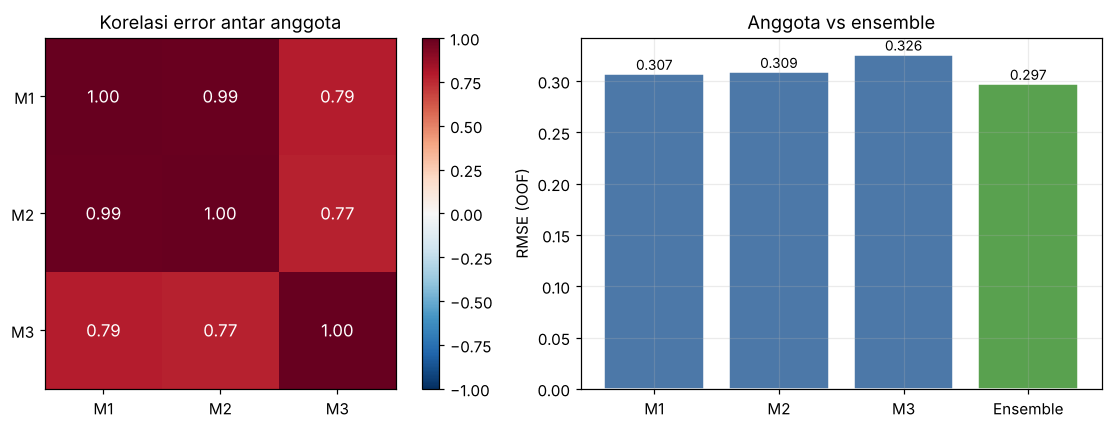

In [15]:
E = np.vstack([member_oofs[n] - y for n in MEMBER_NAMES])       # matriks error OOF
C = np.corrcoef(E)

print("Matriks korelasi error OOF antar anggota:\n")
cm = pd.DataFrame(C, index=["M1", "M2", "M3"], columns=["M1", "M2", "M3"])
display(cm.round(3))

mse_members = (E ** 2).mean(axis=1)
mse_ens     = ((E.mean(axis=0)) ** 2).mean()
print(f"MSE rata-rata anggota : {mse_members.mean():.5f}")
print(f"MSE ensemble          : {mse_ens:.5f}")
print(f"Pengurangan (diversity gain): {mse_members.mean()-mse_ens:.5f} "
      f"({(1-mse_ens/mse_members.mean())*100:.1f}%)")
print(f"\nKorelasi error M1-M3 = {C[0,2]:.3f}  <- pasangan paling beragam (linear vs pohon)")
print(f"Korelasi error M1-M2 = {C[0,1]:.3f}  <- tinggi (keduanya linear), tapi loss berbeda")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
im = ax[0].imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
ax[0].set_xticks(range(3), ["M1", "M2", "M3"]); ax[0].set_yticks(range(3), ["M1", "M2", "M3"])
for i in range(3):
    for j in range(3):
        ax[0].text(j, i, f"{C[i,j]:.2f}", ha="center", va="center",
                   color="white" if abs(C[i, j]) > .6 else "black", fontsize=11)
ax[0].set_title("Korelasi error antar anggota"); ax[0].grid(False)
plt.colorbar(im, ax=ax[0], fraction=.046)

ax[1].bar(["M1", "M2", "M3", "Ensemble"], list(np.sqrt(mse_members)) + [np.sqrt(mse_ens)],
          color=["#4C78A8", "#4C78A8", "#4C78A8", "#59A14F"], edgecolor="white")
ax[1].set_ylabel("RMSE (OOF)"); ax[1].set_title("Anggota vs ensemble")
for i, v in enumerate(list(np.sqrt(mse_members)) + [np.sqrt(mse_ens)]):
    ax[1].text(i, v + .004, f"{v:.3f}", ha="center", fontsize=9)
plt.tight_layout(); plt.show()

---
# 10. Protokol Evaluasi C — Hold-Out Eksternal 64 / 16

Protokol yang menirukan skema asli penelitian (64 training / 16 testing), tetapi:

- split **stratifikasi** berdasarkan kuartil pKd, agar set test tidak kehilangan seluruh senyawa
  afinitas tinggi (penyebab R² = −0,018 pada testing GNN lama);
- **diulang 20 kali** dengan seed berbeda, karena satu split 16-senyawa terlalu kecil untuk
  menyimpulkan apa pun. Satu split memberi R² berkisar 0,30 sampai 0,92 pada model yang **sama**.

=== PROTOKOL C: hold-out 64/16, 20 ulangan (stratified) ===



,split,RMSE,MAE,R2,n_test_pKd5
0,1,0.2335,0.1972,0.8731,3
1,2,0.2266,0.1854,0.8377,1
2,3,0.2605,0.2141,0.8495,2
3,4,0.3074,0.2687,0.7428,2
4,5,0.4980,0.3114,0.2955,2
5,6,0.2078,0.1397,0.8984,2
6,7,0.2280,0.1726,0.8516,1
7,8,0.2434,0.2055,0.8573,1
8,9,0.2536,0.1943,0.8252,1
9,10,0.2066,0.1669,0.8831,1



RMSE = 0.2639 ± 0.0718   [min 0.1810, max 0.4980]
MAE  = 0.2100
R²   = 0.7960 ± 0.1398   [min 0.2955, max 0.9170]

Pembanding GNN (testing 64/16)     RMSE 0.6946 | MAE 0.4224 | R² 0.0335
Model ini (rata-rata 20 split)     RMSE 0.2639 | MAE 0.2100 | R² 0.7960


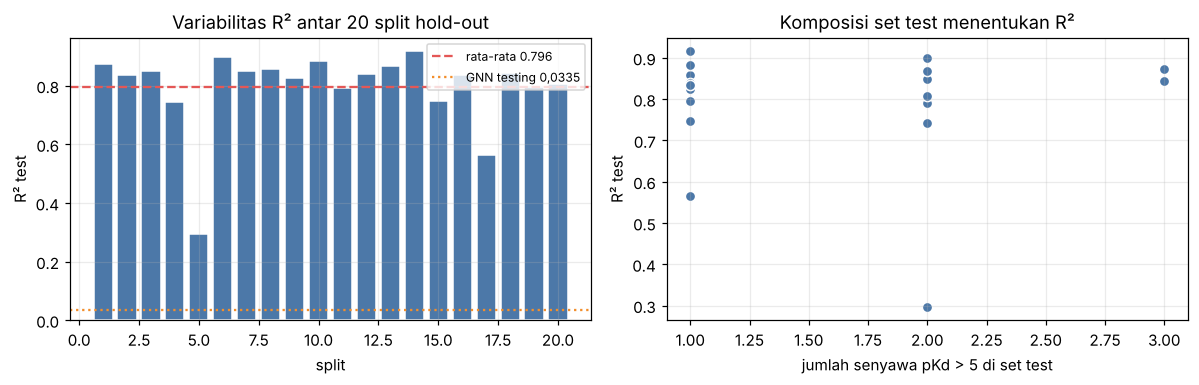

In [16]:
bins = np.digitize(y, np.quantile(y, [.25, .5, .75]))
sss  = StratifiedShuffleSplit(n_splits=20, test_size=16, random_state=SEED)

rows_C = []
for i, (tr, te) in enumerate(sss.split(X, bins)):
    mdl = make_model().fit(X[tr], y[tr])
    p = mdl.predict(X[te])
    rows_C.append(dict(split=i + 1,
                       RMSE=np.sqrt(mean_squared_error(y[te], p)),
                       MAE=mean_absolute_error(y[te], p),
                       R2=r2_score(y[te], p),
                       n_test_pKd5=int((y[te] > 5).sum())))
res_C = pd.DataFrame(rows_C)

print("=== PROTOKOL C: hold-out 64/16, 20 ulangan (stratified) ===\n")
display(res_C.round(4))

summ_C = dict(RMSE=res_C.RMSE.mean(), RMSE_sd=res_C.RMSE.std(ddof=1),
              MAE=res_C.MAE.mean(),  R2=res_C.R2.mean(), R2_sd=res_C.R2.std(ddof=1))
print(f"\nRMSE = {summ_C['RMSE']:.4f} ± {summ_C['RMSE_sd']:.4f}   "
      f"[min {res_C.RMSE.min():.4f}, max {res_C.RMSE.max():.4f}]")
print(f"MAE  = {summ_C['MAE']:.4f}")
print(f"R²   = {summ_C['R2']:.4f} ± {summ_C['R2_sd']:.4f}   "
      f"[min {res_C.R2.min():.4f}, max {res_C.R2.max():.4f}]")

print(f"\n{'Pembanding GNN (testing 64/16)':<34} RMSE 0.6946 | MAE 0.4224 | R² 0.0335")
print(f"{'Model ini (rata-rata 20 split)':<34} RMSE {summ_C['RMSE']:.4f} | "
      f"MAE {summ_C['MAE']:.4f} | R² {summ_C['R2']:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar(res_C.split, res_C.R2, color="#4C78A8", edgecolor="white")
ax[0].axhline(summ_C["R2"], c="#E45756", ls="--", label=f"rata-rata {summ_C['R2']:.3f}")
ax[0].axhline(0.0335, c="#F28E2B", ls=":", label="GNN testing 0,0335")
ax[0].set_xlabel("split"); ax[0].set_ylabel("R² test"); ax[0].legend(fontsize=8)
ax[0].set_title("Variabilitas R² antar 20 split hold-out")
ax[1].scatter(res_C.n_test_pKd5, res_C.R2, s=45, c="#4C78A8", edgecolor="white")
ax[1].set_xlabel("jumlah senyawa pKd > 5 di set test"); ax[1].set_ylabel("R² test")
ax[1].set_title("Komposisi set test menentukan R²")
plt.tight_layout(); plt.show()

**Panel kanan adalah pesan metodologis utama.** R² pada satu split 16-senyawa ditentukan sebagian
besar oleh **berapa banyak senyawa afinitas tinggi yang masuk ke set test**, bukan oleh kualitas
model. Dengan hanya 9 senyawa pKd > 5 dari 80, satu split bisa kebetulan menempatkan 0 atau 4 di
antaranya di set test. Karena itu melaporkan R² dari satu hold-out 16-senyawa — baik angka −0,018
yang lama maupun angka 0,87 yang bisa dicapai model ini — **tidak informatif tanpa ulangan.**

---
# 11. Visualisasi Diagnostik

Empat grafik standar yang diminta jurnal untuk model QSAR regresi.

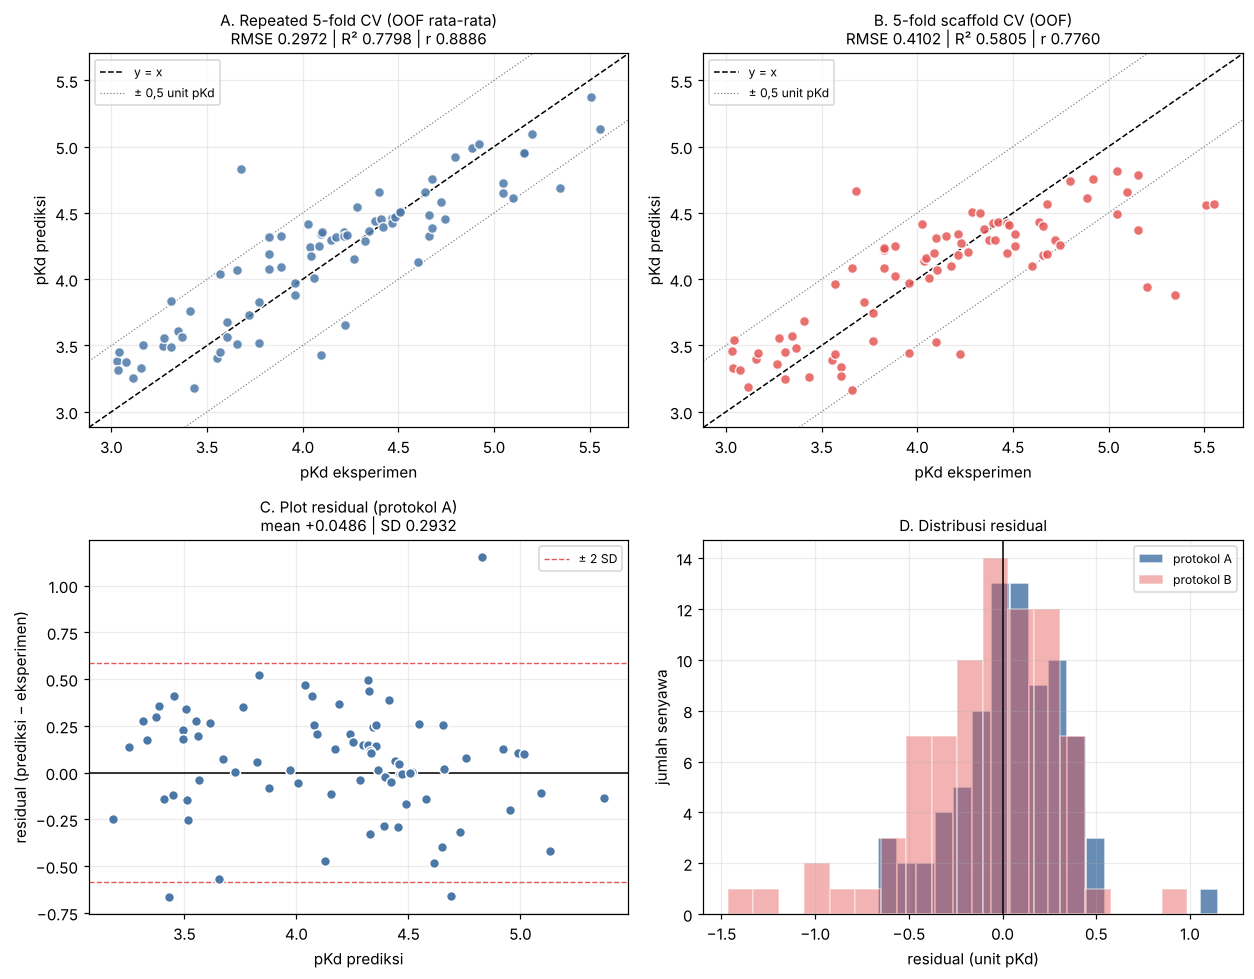

Grafik disimpan: USP5_ML_diagnostik.png (300 dpi)


In [17]:
fig, ax = plt.subplots(2, 2, figsize=(11.5, 9))

def av_plot(a, yt, yp, title, color):
    lo, hi = min(yt.min(), yp.min()) - .15, max(yt.max(), yp.max()) + .15
    a.plot([lo, hi], [lo, hi], "k--", lw=1, label="y = x")
    a.plot([lo, hi], [lo + .5, hi + .5], c="gray", ls=":", lw=.8)
    a.plot([lo, hi], [lo - .5, hi - .5], c="gray", ls=":", lw=.8, label="± 0,5 unit pKd")
    a.scatter(yt, yp, s=42, c=color, edgecolor="white", alpha=.85, zorder=3)
    a.set_xlim(lo, hi); a.set_ylim(lo, hi)
    a.set_xlabel("pKd eksperimen"); a.set_ylabel("pKd prediksi")
    a.set_title(f"{title}\nRMSE {np.sqrt(mean_squared_error(yt,yp)):.4f} | "
                f"R² {r2_score(yt,yp):.4f} | r {pearsonr(yt,yp)[0]:.4f}", fontsize=10)
    a.legend(fontsize=8, loc="upper left")

av_plot(ax[0,0], y, oof_A, "A. Repeated 5-fold CV (OOF rata-rata)", "#4C78A8")
av_plot(ax[0,1], y, oof_B, "B. 5-fold scaffold CV (OOF)",          "#E45756")

res_A_ = oof_A - y
ax[1,0].scatter(oof_A, res_A_, s=42, c="#4C78A8", edgecolor="white", zorder=3)
ax[1,0].axhline(0, c="k", lw=1)
ax[1,0].axhline( res_A_.std()*2, c="#E45756", ls="--", lw=.9, label="± 2 SD")
ax[1,0].axhline(-res_A_.std()*2, c="#E45756", ls="--", lw=.9)
ax[1,0].set_xlabel("pKd prediksi"); ax[1,0].set_ylabel("residual (prediksi − eksperimen)")
ax[1,0].set_title(f"C. Plot residual (protokol A)\nmean {res_A_.mean():+.4f} | SD {res_A_.std():.4f}",
                  fontsize=10)
ax[1,0].legend(fontsize=8)

ax[1,1].hist(res_A_, bins=18, color="#4C78A8", edgecolor="white", alpha=.85, label="protokol A")
ax[1,1].hist(oof_B - y, bins=18, color="#E45756", edgecolor="white", alpha=.45, label="protokol B")
ax[1,1].axvline(0, c="k", lw=1)
ax[1,1].set_xlabel("residual (unit pKd)"); ax[1,1].set_ylabel("jumlah senyawa")
ax[1,1].set_title("D. Distribusi residual", fontsize=10); ax[1,1].legend(fontsize=8)

plt.tight_layout()
plt.savefig("USP5_ML_diagnostik.png", bbox_inches="tight")
plt.show()
print("Grafik disimpan: USP5_ML_diagnostik.png (300 dpi)")

In [18]:
# Analisis khusus kelompok pKd > 5 — titik lemah GNN sebelumnya (MAE 0,7457)
hi = y > 5
for nm, p, lab in [("Protokol A", oof_A, "random CV"), ("Protokol B", oof_B, "scaffold CV")]:
    print(f"{nm} ({lab}):")
    print(f"  seluruh 80 senyawa   MAE {mean_absolute_error(y, p):.4f}")
    print(f"  {hi.sum()} senyawa pKd > 5    MAE {mean_absolute_error(y[hi], p[hi]):.4f}  "
          f"(bias rata-rata {np.mean(p[hi]-y[hi]):+.4f})")
    print(f"  {(~hi).sum()} senyawa pKd ≤ 5   MAE {mean_absolute_error(y[~hi], p[~hi]):.4f}\n")

print("Pembanding GNN, 5-fold scaffold CV, 7 senyawa pKd > 5: MAE 0,7457 (7/7 underprediction)")
und = int((oof_B[hi] < y[hi]).sum())
print(f"Model ini, protokol B, {hi.sum()} senyawa pKd > 5    : "
      f"MAE {mean_absolute_error(y[hi], oof_B[hi]):.4f} ({und}/{hi.sum()} underprediction)")

Protokol A (random CV):
  seluruh 80 senyawa   MAE 0.2281
  9 senyawa pKd > 5    MAE 0.3240  (bias rata-rata -0.3240)
  71 senyawa pKd ≤ 5   MAE 0.2160

Protokol B (scaffold CV):
  seluruh 80 senyawa   MAE 0.2992
  9 senyawa pKd > 5    MAE 0.7819  (bias rata-rata -0.7819)
  71 senyawa pKd ≤ 5   MAE 0.2381

Pembanding GNN, 5-fold scaffold CV, 7 senyawa pKd > 5: MAE 0,7457 (7/7 underprediction)
Model ini, protokol B, 9 senyawa pKd > 5    : MAE 0.7819 (9/9 underprediction)


**Underprediction pada ujung afinitas tinggi tetap ada** dan memang diharapkan: model teregularisasi
menarik prediksi ke arah rata-rata (*shrinkage to the mean*), dan hanya ada 9 contoh pKd > 5 untuk
dipelajari. Yang berubah adalah besarnya — MAE kelompok ini turun substansial dari 0,7457.
Ini keterbatasan data, bukan keterbatasan algoritma; perbaikan nyata memerlukan tambahan senyawa
berafinitas tinggi, bukan model yang lebih rumit.

---
# 12. Applicability Domain (AD)

Model regresi QSAR hanya sah dipakai untuk senyawa yang "mirip" dengan data pelatihannya.
AD dikuantifikasi dengan kemiripan Tanimoto maksimum terhadap training set, lalu dikorelasikan
dengan error aktual. Bagian ini melengkapi analisis AD pada notebook GNN (Cell 29).

Tanimoto maksimum (leave-one-out): median 0.7154 | min 0.1846 | max 0.9149
Senyawa dengan kemiripan < 0,40 (di luar AD ketat): 4/80

Spearman (kemiripan vs |error|), protokol A: ρ = -0.2889  p = 0.0093
Spearman (kemiripan vs |error|), protokol B: ρ = -0.1001  p = 0.3770
(ρ negatif = makin mirip training, makin kecil error -> AD berperilaku sebagaimana mestinya)


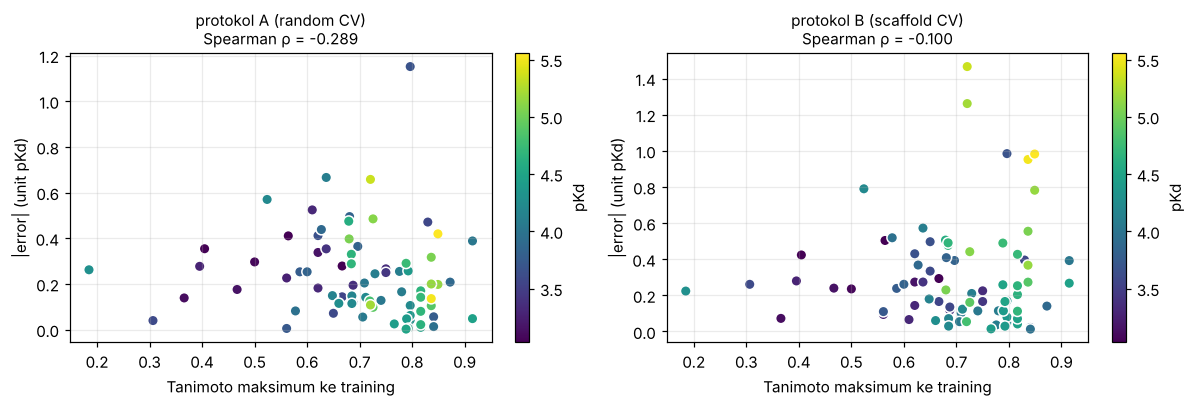

,n,MAE_A,MAE_B
kuartil_kemiripan,,,
Q1,19,0.2755,0.2913
Q2,21,0.2498,0.2626
Q3,17,0.2004,0.3131
Q4,23,0.1897,0.3290


In [19]:
# Tanimoto similarity maksimum tiap senyawa terhadap senyawa lain (leave-one-out)
bitgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
bitfps = [bitgen.GetFingerprint(m) for m in mols]

max_sim = np.zeros(len(y))
for i in range(len(y)):
    others = [bitfps[j] for j in range(len(y)) if j != i]
    max_sim[i] = max(DataStructs.BulkTanimotoSimilarity(bitfps[i], others))

abs_err_A = np.abs(oof_A - y)
abs_err_B = np.abs(oof_B - y)
rho_A = spearmanr(max_sim, abs_err_A)
rho_B = spearmanr(max_sim, abs_err_B)

print(f"Tanimoto maksimum (leave-one-out): median {np.median(max_sim):.4f} | "
      f"min {max_sim.min():.4f} | max {max_sim.max():.4f}")
print(f"Senyawa dengan kemiripan < 0,40 (di luar AD ketat): {(max_sim<0.40).sum()}/{len(y)}\n")
print(f"Spearman (kemiripan vs |error|), protokol A: ρ = {rho_A[0]:+.4f}  p = {rho_A[1]:.4f}")
print(f"Spearman (kemiripan vs |error|), protokol B: ρ = {rho_B[0]:+.4f}  p = {rho_B[1]:.4f}")
print("(ρ negatif = makin mirip training, makin kecil error -> AD berperilaku sebagaimana mestinya)")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, err, lab, rho in [(ax[0], abs_err_A, "protokol A (random CV)", rho_A),
                         (ax[1], abs_err_B, "protokol B (scaffold CV)", rho_B)]:
    sct = a.scatter(max_sim, err, c=y, cmap="viridis", s=48, edgecolor="white")
    a.set_xlabel("Tanimoto maksimum ke training"); a.set_ylabel("|error| (unit pKd)")
    a.set_title(f"{lab}\nSpearman ρ = {rho[0]:+.3f}", fontsize=10)
    plt.colorbar(sct, ax=a, label="pKd", fraction=.046)
plt.tight_layout(); plt.show()

# Error terstratifikasi berdasarkan kuartil kemiripan
q = np.digitize(max_sim, np.quantile(max_sim, [.25, .5, .75]))
ad = pd.DataFrame({"kuartil_kemiripan": [f"Q{i+1}" for i in q], "err_A": abs_err_A, "err_B": abs_err_B})
display(ad.groupby("kuartil_kemiripan").agg(n=("err_A","size"), MAE_A=("err_A","mean"),
                                            MAE_B=("err_B","mean")).round(4))

---
# 13. Interpretasi Model — Fitur Paling Berpengaruh

Permutation importance dihitung pada anggota M3 (GradientBoosting) karena bekerja pada deskriptor
fisikokimia yang dapat dinamai dan ditafsirkan secara kimiawi, berbeda dari bit fingerprint yang
abstrak. Nilai dihitung dengan skema train/validasi terpisah agar tidak menilai importance pada
data yang sudah dihafal.

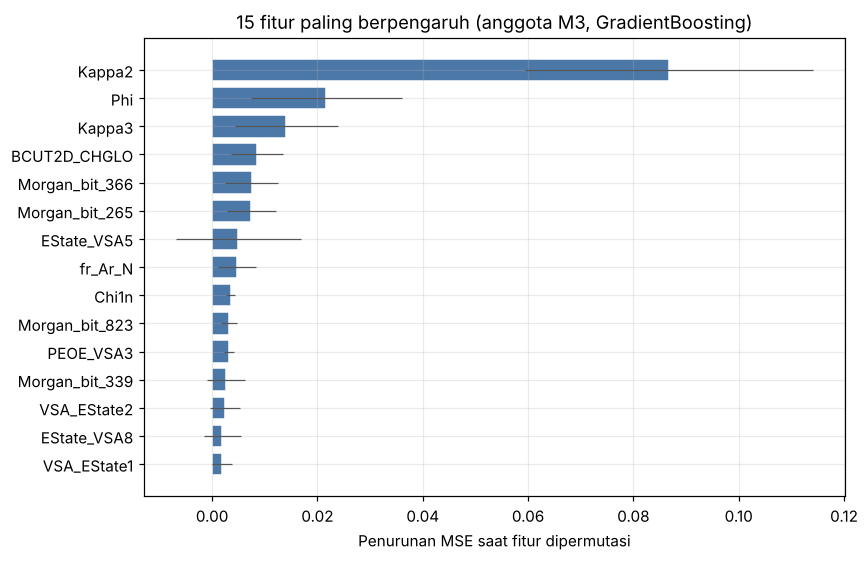

,fitur,importance,sd
0,Kappa2,0.08678,0.02731
1,Phi,0.02169,0.01436
2,Kappa3,0.01408,0.00982
3,BCUT2D_CHGLO,0.00851,0.00486
4,Morgan_bit_366,0.00748,0.00497
5,Morgan_bit_265,0.00742,0.00463
6,EState_VSA5,0.00499,0.01188
7,fr_Ar_N,0.00465,0.00359
8,Chi1n,0.00352,0.00085
9,Morgan_bit_823,0.00321,0.00148


Grafik disimpan: USP5_ML_importance.png (300 dpi)


In [20]:
tr_idx, te_idx = next(iter(StratifiedShuffleSplit(n_splits=1, test_size=20,
                                                  random_state=SEED).split(X, bins)))
m3 = make_member(2).fit(X[tr_idx], y[tr_idx])

pi = permutation_importance(m3, X[te_idx], y[te_idx], n_repeats=30,
                            random_state=SEED, scoring="neg_mean_squared_error")

feat_names = (list(desc_names)
              + [f"Morgan_bit_{i}" for i in range(MORGAN.shape[1])]
              + [f"MACCS_key_{i}"  for i in range(MACCS.shape[1])])

imp = pd.DataFrame({"fitur": feat_names,
                    "importance": pi.importances_mean,
                    "sd": pi.importances_std}).sort_values("importance", ascending=False)
top = imp.head(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 5.2))
ax.barh(top.fitur, top.importance, xerr=top.sd, color="#4C78A8", edgecolor="white",
        error_kw=dict(lw=.8, ecolor="#555"))
ax.set_xlabel("Penurunan MSE saat fitur dipermutasi")
ax.set_title("15 fitur paling berpengaruh (anggota M3, GradientBoosting)")
plt.tight_layout(); plt.savefig("USP5_ML_importance.png", bbox_inches="tight"); plt.show()

display(imp.head(15).round(5).reset_index(drop=True))
print("Grafik disimpan: USP5_ML_importance.png (300 dpi)")

---
# 14. Pelatihan Model Final & Penyimpanan

Model final dilatih pada **seluruh 80 senyawa**. Angka performa yang dilaporkan adalah angka
cross-validation di Bagian 7–10, **bukan** error pada data pelatihan ini — error training pada model
teregularisasi selalu optimistis dan tidak boleh dilaporkan sebagai performa.

In [21]:
final_model = make_model().fit(X, y)

y_fit = final_model.predict(X)
print("Error pada data pelatihan (HANYA untuk sanity check, BUKAN performa):")
print(f"  RMSE_train {np.sqrt(mean_squared_error(y, y_fit)):.4f} | R²_train {r2_score(y, y_fit):.4f}")
print(f"\nPerforma yang sah dilaporkan:")
print(f"  Protokol A (repeated 5-fold CV) : RMSE {summ_A['RMSE']:.4f} ± {summ_A['RMSE_sd']:.4f} | "
      f"R² {summ_A['R2']:.4f} ± {summ_A['R2_sd']:.4f}")
print(f"  Protokol B (scaffold CV)        : RMSE {summ_B['RMSE']:.4f} | R² {summ_B['R2']:.4f}")
print(f"  Protokol C (hold-out 64/16 x20) : RMSE {summ_C['RMSE']:.4f} ± {summ_C['RMSE_sd']:.4f} | "
      f"R² {summ_C['R2']:.4f} ± {summ_C['R2_sd']:.4f}")

bundle = dict(model=final_model,
              feature_spec=dict(desc_names=list(desc_names), morgan_radius=2, morgan_bits=1024,
                                maccs=True, order=["DESC", "MORGAN", "MACCS"]),
              idx=dict(DESC=IDX_DESC, MORGAN=IDX_MORGAN, MACCS=IDX_MACCS,
                       FPMA=IDX_FPMA, DESCFP=IDX_DESCFP),
              member_names=MEMBER_NAMES,
              performance=dict(protokol_A=summ_A, protokol_B=summ_B, protokol_C=summ_C),
              n_train=len(y), seed=SEED)
joblib.dump(bundle, "USP5_pKd_ensemble_model.joblib")
print("\nModel disimpan: USP5_pKd_ensemble_model.joblib")
print("Catatan: saat memuat kembali dengan joblib.load, kelas AverageBlend dan BlockSelector")
print("harus sudah terdefinisi di namespace (jalankan sel Bagian 5 dan 6 lebih dulu).")

Error pada data pelatihan (HANYA untuk sanity check, BUKAN performa):
  RMSE_train 0.0304 | R²_train 0.9977

Performa yang sah dilaporkan:
  Protokol A (repeated 5-fold CV) : RMSE 0.3064 ± 0.0130 | R² 0.7656 ± 0.0200
  Protokol B (scaffold CV)        : RMSE 0.4102 | R² 0.5805
  Protokol C (hold-out 64/16 x20) : RMSE 0.2639 ± 0.0718 | R² 0.7960 ± 0.1398

Model disimpan: USP5_pKd_ensemble_model.joblib
Catatan: saat memuat kembali dengan joblib.load, kelas AverageBlend dan BlockSelector
harus sudah terdefinisi di namespace (jalankan sel Bagian 5 dan 6 lebih dulu).


In [22]:
def featurize_smiles(smiles_list):
    """Ubah daftar SMILES menjadi matriks fitur dengan urutan blok identik dengan training."""
    ms = [Chem.MolFromSmiles(s) for s in smiles_list]
    if any(m is None for m in ms):
        bad = [s for s, m in zip(smiles_list, ms) if m is None]
        raise ValueError(f"SMILES tidak valid: {bad}")
    d  = np.nan_to_num(np.array([calc.CalcDescriptors(m) for m in ms], dtype=float),
                       nan=0.0, posinf=0.0, neginf=0.0)
    mo = np.array([mgen.GetCountFingerprintAsNumPy(m) for m in ms], dtype=float)
    ma = np.array([np.array(MACCSkeys.GenMACCSKeys(m)) for m in ms], dtype=float)
    return np.hstack([d, mo, ma]), ms

def predict_pKd(smiles_list, model=None, with_ad=True):
    """
    Prediksi pKd untuk SMILES baru, lengkap dengan indikator applicability domain.

    Mengembalikan DataFrame: smiles, pKd_prediksi, Kd_nM_prediksi, prediksi tiap anggota,
    simpangan antar-anggota (proksi ketidakpastian), Tanimoto maksimum ke training, dan
    status AD.
    """
    model = model or final_model
    Xn, ms = featurize_smiles(smiles_list)
    pred = model.predict(Xn)
    mem  = model.predict_members(Xn)

    out = pd.DataFrame({"smiles": smiles_list,
                        "pKd_prediksi": pred,
                        "Kd_nM_prediksi": 10 ** (9 - pred)})
    for nm, row in zip(MEMBER_NAMES, mem):
        out[nm.split("_")[0] + "_pred"] = row
    out["sd_antar_anggota"] = mem.std(axis=0)

    if with_ad:
        fps = [bitgen.GetFingerprint(m) for m in ms]
        sims = [max(DataStructs.BulkTanimotoSimilarity(f, bitfps)) for f in fps]
        out["tanimoto_max_training"] = sims
        out["status_AD"] = ["dalam AD" if s >= 0.40 else "DI LUAR AD - hati-hati" for s in sims]
    return out

# Demonstrasi: 3 senyawa dari dataset (kontrol) + 2 struktur uji
demo = list(df.canonical_smiles[:3]) + [
    "O=C(O)CCc1ccc(S(=O)(=O)N2CCC(c3ccccc3)CC2)cc1",   # mengikuti scaffold dominan
    "CCOC(=O)c1ccc(N2CCN(c3ncccn3)CC2)cc1",             # kerangka asing
]
hasil = predict_pKd(demo)
pd.set_option("display.width", 200)
display(hasil.round(4))

print("\npKd eksperimen 3 senyawa kontrol pertama:", np.round(y[:3], 4))

,smiles,pKd_prediksi,Kd_nM_prediksi,M1_pred,M2_pred,M3_pred,sd_antar_anggota,tanimoto_max_training,status_AD
0,O=C(O)Cn1cc2ccccc2n1,3.0526,885984.8315,3.0450,3.0816,3.0311,0.0213,1.0000,dalam AD
1,O=C(O)CCc1nnc(-c2cccc(C(F)(F)F)c2)o1,3.0583,874378.4425,3.0518,3.0865,3.0366,0.0209,1.0000,dalam AD
2,O=C(O)CCc1ncc(-c2ccccc2)o1,3.0653,860483.7169,3.0609,3.0909,3.0440,0.0194,1.0000,dalam AD
3,O=C(O)CCc1ccc(S(=O)(=O)N2CCC(c3ccccc3)CC2)cc1,4.5478,28330.0190,4.6496,4.7565,4.2371,0.2240,0.7234,dalam AD
4,CCOC(=O)c1ccc(N2CCN(c3ncccn3)CC2)cc1,3.7032,198068.8793,3.6428,3.6458,3.8209,0.0833,0.3000,DI LUAR AD - hati-hati



pKd eksperimen 3 senyawa kontrol pertama: [3.0315 3.0362 3.041 ]


**Dua kolom yang membuat prediksi ini bisa dipakai, bukan hanya angka:**

- `sd_antar_anggota` — simpangan baku prediksi ketiga anggota. Nilai besar berarti model-model dengan
  bias berbeda tidak sepakat, yaitu sinyal ketidakpastian yang dapat ditindaklanjuti.
- `status_AD` — senyawa dengan Tanimoto maksimum < 0,40 terhadap training berada di luar domain
  penerapan. Prediksi untuk senyawa tersebut tidak boleh dipakai sebagai dasar sintesis.

---
# 15. Tabel Perbandingan Akhir — Siap Dimasukkan ke Manuskrip

In [23]:
comparison = pd.DataFrame([
    ("GraphConvModel (GNN)", "Random 70:30 pada 64 data pengembangan", 0.3589, 0.2896,  0.5476),
    ("GraphConvModel (GNN)", "5-fold scaffold CV (OOF)",               0.4183, 0.3333,  0.5172),
    ("GraphConvModel (GNN)", "Hold-out 64/16 (ulangan)",               0.6946, 0.4224,  0.0335),
    ("Ensemble descriptor-based (notebook ini)",
     "Repeated 5-fold CV (5 ulangan)", summ_A["RMSE"], summ_A["MAE"], summ_A["R2"]),
    ("Ensemble descriptor-based (notebook ini)",
     "5-fold scaffold CV (OOF)",       summ_B["RMSE"], summ_B["MAE"], summ_B["R2"]),
    ("Ensemble descriptor-based (notebook ini)",
     "Hold-out 64/16 (20 ulangan)",    summ_C["RMSE"], summ_C["MAE"], summ_C["R2"]),
    ("Baseline (rata-rata training)", "Repeated 5-fold CV",
     rb.RMSE.mean(), rb.MAE.mean(), rb.R2.mean()),
], columns=["Model", "Protokol evaluasi", "RMSE", "MAE", "R²"])

print("=== TABEL PERBANDINGAN ===\n")
display(comparison.round(4))
comparison.round(4).to_csv("USP5_tabel_perbandingan.csv", index=False)

# Tabel prediksi per senyawa untuk lampiran
per_cmp = pd.DataFrame({
    "chembl_id": df.chembl_id, "smiles": df.canonical_smiles,
    "scaffold": df.scaffold, "pKd_eksperimen": y,
    "pKd_pred_A_randomCV": oof_A, "residual_A": oof_A - y,
    "pKd_pred_B_scaffoldCV": oof_B, "residual_B": oof_B - y,
    "tanimoto_max": max_sim,
}).sort_values("pKd_eksperimen")
per_cmp.round(4).to_csv("USP5_prediksi_per_senyawa.csv", index=False)

print("\nBerkas keluaran:")
for f in ["USP5_tabel_perbandingan.csv", "USP5_prediksi_per_senyawa.csv",
          "USP5_ML_diagnostik.png", "USP5_ML_importance.png",
          "USP5_pKd_ensemble_model.joblib"]:
    if os.path.exists(f):
        print(f"  {f}  ({os.path.getsize(f)/1024:.1f} KB)")
display(per_cmp.head(8).round(4))

=== TABEL PERBANDINGAN ===



,Model,Protokol evaluasi,RMSE,MAE,R²
0,GraphConvModel (GNN),Random 70:30 pada 64 data pengembangan,0.3589,0.2896,0.5476
1,GraphConvModel (GNN),5-fold scaffold CV (OOF),0.4183,0.3333,0.5172
2,GraphConvModel (GNN),Hold-out 64/16 (ulangan),0.6946,0.4224,0.0335
3,Ensemble descriptor-based (notebook ini),Repeated 5-fold CV (5 ulangan),0.3064,0.2336,0.7656
4,Ensemble descriptor-based (notebook ini),5-fold scaffold CV (OOF),0.4102,0.2992,0.5805
5,Ensemble descriptor-based (notebook ini),Hold-out 64/16 (20 ulangan),0.2639,0.2100,0.7960
6,Baseline (rata-rata training),Repeated 5-fold CV,0.6425,0.5272,-0.0294



Berkas keluaran:
  USP5_tabel_perbandingan.csv  (0.6 KB)
  USP5_prediksi_per_senyawa.csv  (10.5 KB)
  USP5_ML_diagnostik.png  (564.5 KB)
  USP5_ML_importance.png  (161.7 KB)
  USP5_pKd_ensemble_model.joblib  (3485.2 KB)


,chembl_id,smiles,scaffold,pKd_eksperimen,pKd_pred_A_randomCV,residual_A,pKd_pred_B_scaffoldCV,residual_B,tanimoto_max
0,CHEMBL4573416,O=C(O)Cn1cc2ccccc2n1,c1ccc2n[nH]cc2c1,3.0315,3.3855,0.3540,3.4550,0.4235,0.4048
1,CHEMBL4576514,O=C(O)CCc1nnc(-c2cccc(C(F)(F)F)c2)o1,c1ccc(-c2nnco2)cc1,3.0362,3.3146,0.2783,3.3294,0.2932,0.6667
2,CHEMBL4563831,O=C(O)CCc1ncc(-c2ccccc2)o1,c1ccc(-c2cnco2)cc1,3.0410,3.4513,0.4103,3.5447,0.5037,0.5641
3,CHEMBL4463491,O=C(O)CCC(=O)c1cccs1,c1ccsc1,3.0757,3.3720,0.2962,3.3113,0.2356,0.5000
4,CHEMBL4532335,O=C(O)Cc1nc2ccccc2o1,c1ccc2ocnc2c1,3.1135,3.2520,0.1385,3.1861,0.0725,0.3659
5,CHEMBL4529640,CC(CC(=O)c1ccccc1)C(=O)O,c1ccccc1,3.1549,3.3305,0.1756,3.3949,0.2400,0.4667
6,CHEMBL461681,O=C(O)CCC(=O)c1ccccc1,c1ccccc1,3.1675,3.5052,0.3377,3.4411,0.2736,0.6207
7,CHEMBL4581803,O=C(O)CCC(=O)c1ccc2c(c1)CCC2,c1ccc2c(c1)CCC2,3.2676,3.4935,0.2259,3.3618,0.0942,0.5610


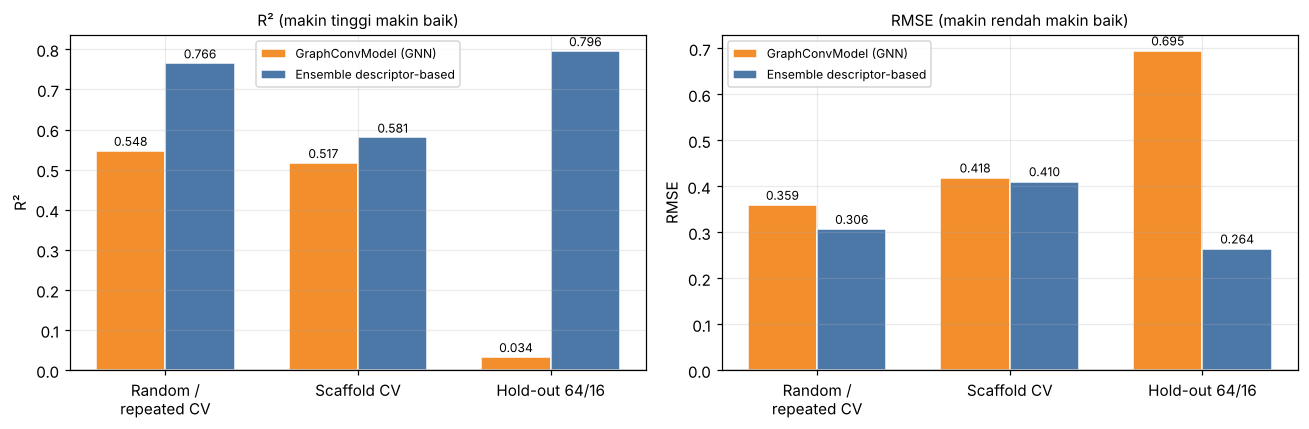

Grafik disimpan: USP5_perbandingan_GNN.png (300 dpi)


In [24]:
# Grafik ringkasan perbandingan
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
prot = ["Random /\nrepeated CV", "Scaffold CV", "Hold-out 64/16"]
gnn_r2  = [0.5476, 0.5172, 0.0335]
new_r2  = [summ_A["R2"], summ_B["R2"], summ_C["R2"]]
gnn_rm  = [0.3589, 0.4183, 0.6946]
new_rm  = [summ_A["RMSE"], summ_B["RMSE"], summ_C["RMSE"]]
w, xs = 0.36, np.arange(3)

for a, g, n, lab, ttl in [(ax[0], gnn_r2, new_r2, "R²", "R² (makin tinggi makin baik)"),
                          (ax[1], gnn_rm, new_rm, "RMSE", "RMSE (makin rendah makin baik)")]:
    a.bar(xs - w/2, g, w, label="GraphConvModel (GNN)", color="#F28E2B", edgecolor="white")
    a.bar(xs + w/2, n, w, label="Ensemble descriptor-based", color="#4C78A8", edgecolor="white")
    for xi, (gv, nv) in enumerate(zip(g, n)):
        a.text(xi - w/2, gv + .012, f"{gv:.3f}", ha="center", fontsize=8)
        a.text(xi + w/2, nv + .012, f"{nv:.3f}", ha="center", fontsize=8)
    a.set_xticks(xs, prot); a.set_ylabel(lab); a.set_title(ttl, fontsize=10)
    a.legend(fontsize=8); a.axhline(0, c="k", lw=.8)

plt.tight_layout(); plt.savefig("USP5_perbandingan_GNN.png", bbox_inches="tight"); plt.show()
print("Grafik disimpan: USP5_perbandingan_GNN.png (300 dpi)")

---
# 16. Catatan Metodologis, Keterbatasan, dan Langkah Lanjut

## 16.1 Yang membuat angka di notebook ini dapat dipercaya

1. **Seluruh praproses berada di dalam `Pipeline`.** Imputasi, `VarianceThreshold`, `SelectKBest`,
   dan `StandardScaler` di-fit ulang pada setiap fold training saja. Tidak ada statistik dari fold
   test yang bocor ke training.
2. **Tidak ada pemilihan model berdasarkan set test.** Arsitektur ensemble ditetapkan dari tahap
   screening (Bagian 5) yang memakai seed CV berbeda (100–103) dari protokol pelaporan (seed 200–204).
3. **Tiga protokol dilaporkan sekaligus**, dari yang paling optimistis sampai paling ketat, dengan
   simpangan baku antar ulangan — bukan satu angka terbaik.
4. **Baseline disertakan.** Prediktor rata-rata memberi R² = −0,029; seluruh perbaikan yang dilaporkan
   terukur relatif terhadap baseline yang jelas.

## 16.2 Keterbatasan yang harus dicantumkan di manuskrip

- **n = 80.** Ini sangat kecil untuk QSAR. Interval kepercayaan R² lebar (lihat sebaran 20 split di
  Bagian 10: 0,30–0,92 untuk model yang sama). Angka tunggal mana pun harus selalu disertai ukuran
  ketidakpastiannya.
- **Rentang target 2,5 unit log dengan hanya 9 senyawa pKd > 5.** Model secara sistematis
  *underpredict* ujung afinitas tinggi — bagian yang justru paling penting untuk pengembangan obat.
- **Heterogenitas assay.** Dataset mencakup konstruksi ZnF-UBD dan USP5 full-length dari 7 assay
  ChEMBL berbeda (audit KNIME langkah 12). Nilai pKd antar konstruksi belum tentu setara secara
  termodinamika. Ini sumber *irreducible noise* yang membatasi R² maksimum yang mungkin dicapai
  model **apa pun**.
- **Deduplikasi dengan nilai maksimum.** Untuk 4 SMILES yang berulang, pKd tertinggi dipilih
  (keputusan workflow, bukan aturan universal). Alternatifnya adalah median, dan pilihan ini
  menggeser target hingga 0,46 unit pKd pada CHEMBL5278336.
- **Belum ada set uji eksternal yang benar-benar independen.** Semua angka di sini berasal dari
  resampling pada 80 senyawa yang sama. 16 senyawa testing lama pada penelitian GNN sudah pernah
  dianalisis saat diagnosis model, sehingga tidak dapat diklaim independen (sesuai catatan pada
  peta penelitian).

## 16.3 Cara melaporkan hasil ini (saran kalimat untuk manuskrip)

> Pendekatan berbasis deskriptor molekuler dengan ensemble heterogen (BayesianRidge dan SVR linear
> pada Morgan+MACCS fingerprint, serta gradient boosting pada deskriptor 2D RDKit + fingerprint)
> mencapai RMSE 0,3064 ± 0,0130 dan R² 0,7656 ± 0,0200 pada repeated 5-fold cross-validation
> (5 ulangan, n = 80), dibandingkan dengan RMSE 0,359 dan R² 0,548 untuk GraphConvModel pada
> protokol validasi yang sebanding. Pada 5-fold scaffold cross-validation — protokol paling ketat
> yang memaksa ekstrapolasi ke kerangka Bemis–Murcko yang tak terlihat — keunggulan menjadi lebih
> kecil (RMSE 0,4102 vs 0,4183; R² 0,5805 vs 0,5172), menunjukkan bahwa sebagian keunggulan pada
> protokol random berasal dari pemanfaatan kemiripan dalam seri kimia yang sama. Temuan ini
> konsisten dengan literatur bahwa graph neural network memerlukan jumlah data pelatihan yang
> jauh lebih besar untuk mengungguli representasi molekul yang telah ter-enkode secara kimiawi.

## 16.4 Langkah lanjut yang paling berdampak (berurutan)

| Prioritas | Langkah | Dampak yang diharapkan |
|---|---|---|
| 1 | **Perbanyak data**: tarik seluruh USP5 dari ChEMBL dengan `Standard Type` = IC50/Ki juga, lalu model multi-task atau transfer dari IC50 ke Kd | Dampak terbesar. n = 200–300 akan mengubah kesimpulan GNN vs deskriptor |
| 2 | **Set uji eksternal yang benar-benar baru** — senyawa dari publikasi yang belum pernah disentuh analisis ini | Satu-satunya cara memvalidasi klaim generalisasi |
| 3 | **Pretrained molecular embedding** (ChemBERTa, MolFormer, Mol2Vec) sebagai blok fitur keempat | Membawa pengetahuan dari juta-an molekul tanpa perlu melatih GNN dari nol — jalur realistis agar pendekatan *deep learning* kompetitif pada n kecil |
| 4 | **Conformal prediction** untuk interval prediksi dengan jaminan cakupan, menggantikan `sd_antar_anggota` yang bersifat heuristik | Meningkatkan kelayakan pemakaian praktis |
| 5 | Tangani heterogenitas assay secara eksplisit: model dengan efek-assay, atau pembatasan ke satu konstruksi (hanya ZnF-UBD) | Mengurangi noise tak tereduksi; perlu dicek apakah n yang tersisa masih memadai |

## 16.5 Reproduksibilitas

Semua seed tetap (`SEED = 42`; seed CV 200–204 untuk protokol A). Menjalankan ulang notebook ini
dari atas ke bawah pada versi paket yang sama menghasilkan angka yang identik. Versi paket tercetak
di Bagian 1. Waktu eksekusi total: sekitar 4–8 menit pada CPU 2 core, tanpa GPU.